### Paso 1. Binarización

In [4]:
# Importar librerías
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


Número de objetos detectados con vecindad-4: 2
Número de objetos detectados con vecindad-8: 2


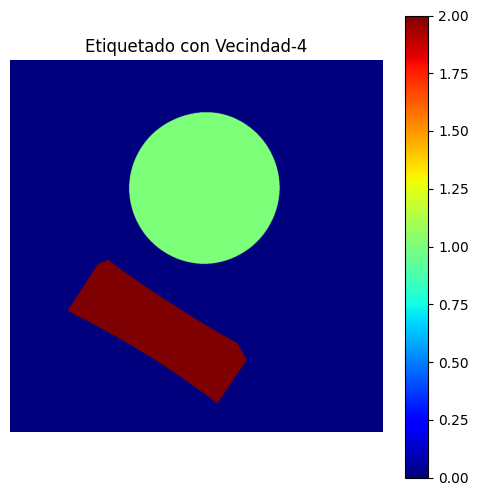

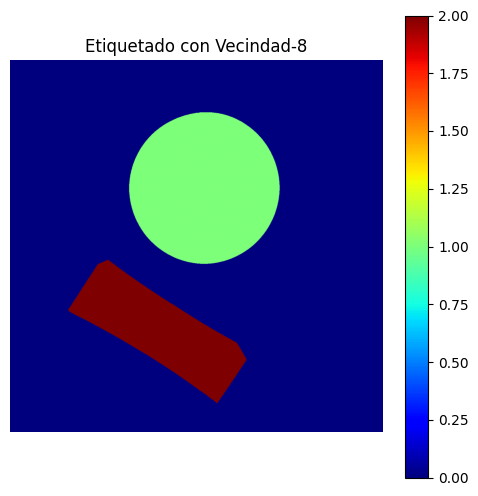

In [5]:

# ----- 2. Etiquetado de componentes conexas -----
img="filtro_maximo_minimo.png"
imagee = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
image = imagee[8:-8, 8:-8]

# Vecindad-4
num_labels_4, labels_4 = cv2.connectedComponents(image, connectivity=4)
# Vecindad-8
num_labels_8, labels_8 = cv2.connectedComponents(image, connectivity=8)
print(f"Número de objetos detectados con vecindad-4: {num_labels_4 - 1}")
print(f"Número de objetos detectados con vecindad-8: {num_labels_8 - 1}")




# Mostrar resultados de vecindad-4
plt.figure(figsize=(6, 6))
plt.imshow(labels_4, cmap='jet')
plt.title('Etiquetado con Vecindad-4')
plt.colorbar()
plt.axis('off')
plt.show()

# Mostrar resultados de vecindad-8
plt.figure(figsize=(6, 6))
plt.imshow(labels_8, cmap='jet')
plt.title('Etiquetado con Vecindad-8')
plt.colorbar()
plt.axis('off')
plt.show()


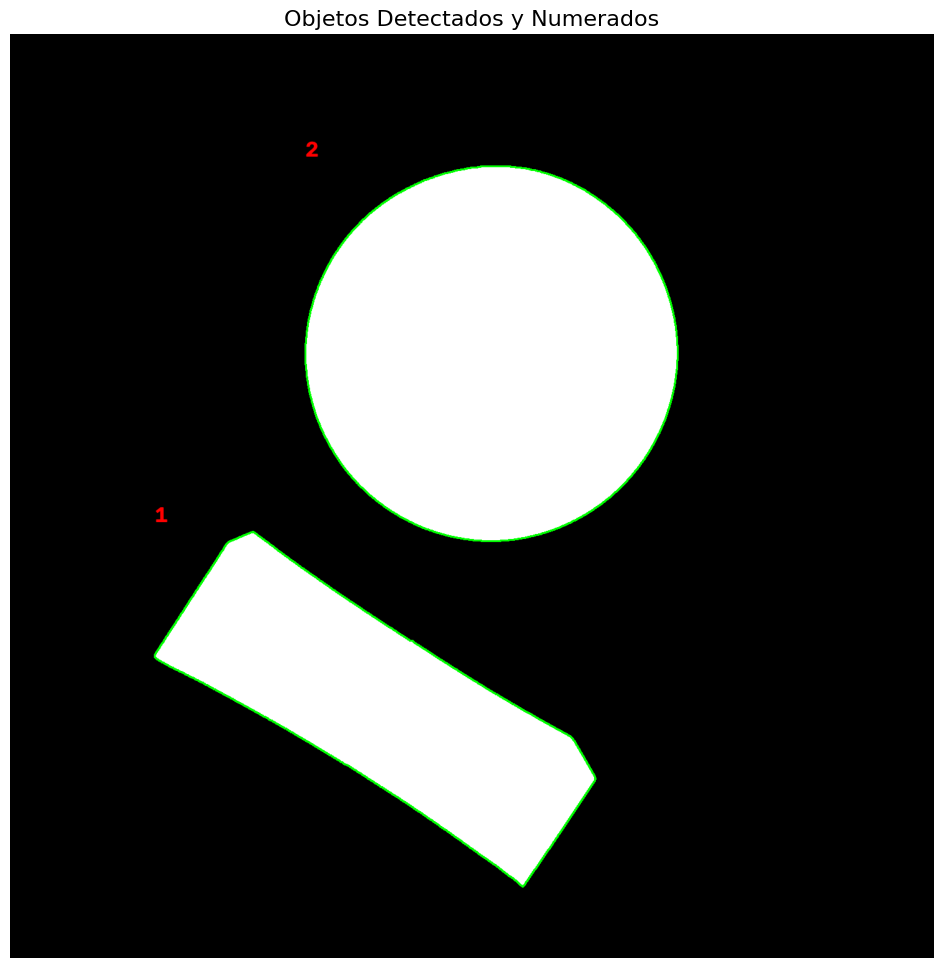

Diferencia entre vecindad-4 y vecindad-8: 0


In [6]:
# ----- 3. Dibujar contornos y numerar los objetos -----

# Convertir imagen binaria a imagen en color
image_color = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

# Encontrar contornos
contours, _ = cv2.findContours(
    image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Dibujar contornos y numerar objetos
for i, contour in enumerate(contours):

    # Dibujar contorno verde
    cv2.drawContours(image_color, [contour], -1, (0, 255, 0), 2)

    # Encontrar posición del objeto
    x, y, w, h = cv2.boundingRect(contour)

    # Posición del número
    texto = f'{i + 1}'
    posicion = (x, max(y - 15, 25))

    # Dibujar fondo negro para el número
    cv2.putText(
        image_color, texto, posicion,
        cv2.FONT_HERSHEY_SIMPLEX, 1.2,
        (0, 0, 0), 6
    )

    # Dibujar número rojo más grande
    cv2.putText(
        image_color, texto, posicion,
        cv2.FONT_HERSHEY_SIMPLEX, 1.2,
        (0, 0, 255), 3
    )

# Mostrar imagen
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB))
plt.title('Objetos Detectados y Numerados', fontsize=16)
plt.axis('off')
plt.show()

# ----- 4. Comparación entre vecindad-4 y vecindad-8 -----

diferencia = abs(num_labels_4 - num_labels_8)
print(f"Diferencia entre vecindad-4 y vecindad-8: {diferencia}")

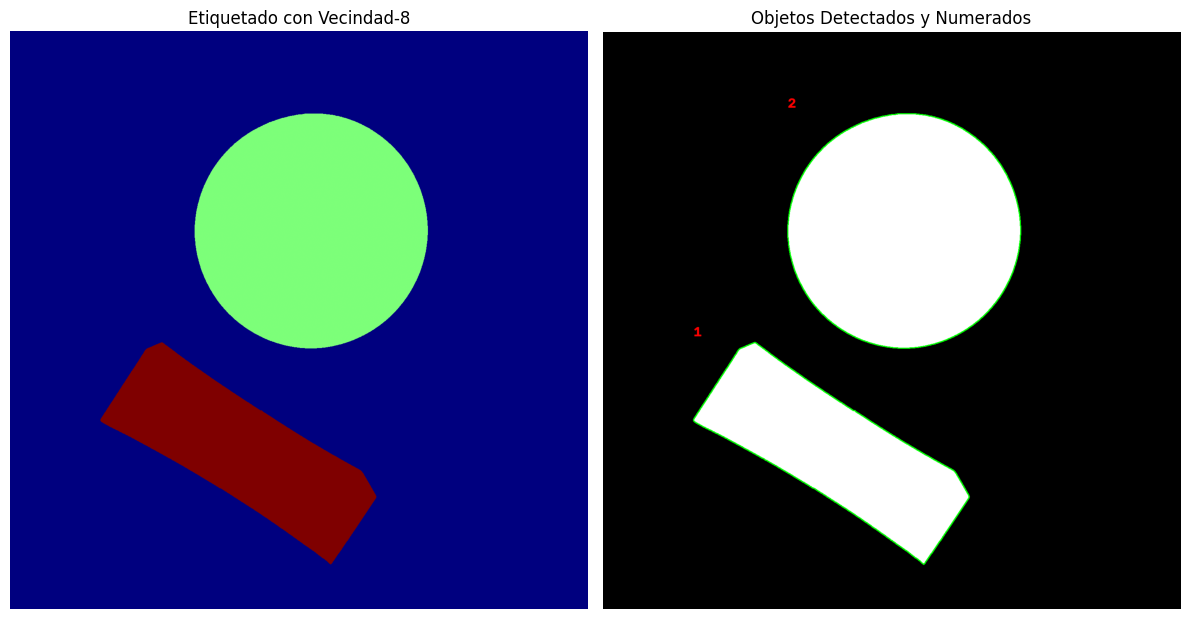

In [23]:
#RESULTADOS
fig, axes = plt.subplots(1, 2, figsize=(12, 10))

# Imagen original
axes[0].imshow(labels_8, cmap='jet')
axes[0].set_title('Etiquetado con Vecindad-8')
axes[0].axis('off')

# Vecindad 8
axes[1].imshow(cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB))
axes[1].set_title('Objetos Detectados y Numerados')
axes[1].axis('off')



plt.tight_layout()
plt.show()

In [ ]:
#Segmentación de elementos en color
# Importar librerías
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Crear una imagen RGBA con fondo transparente
img="filtro_maximo_minimo.png"
imagee = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
image = imagee[8:-8, 8:-8]

# Leer imagen original a color
imagen_og = cv2.imread('img.jpeg')
imagen_original=imagen_og[8:-8, 8:-8]

# Crear fondo amarillo (formato BGR)
fondo_amarillo = np.full_like(imagen_original, (168, 193, 45))

# Aplicar los elementos originales sobre el fondo amarillo
imagen_segmentada = np.where(
    image[:, :, np.newaxis] > 0,
    imagen_original,
    fondo_amarillo
)

# Guardar resultado en PNG
cv2.imwrite('elementos_segmentados_color.png', imagen_segmentada)

True